#**PDBe API Training**

## PDBe Ligand Interactions for a given protein
This tutorial will guide you through searching PDBe for ligand interactions programmatically.

##Setup

First we will import the code which is required to search the API and plot the results.

Run the cell below by pressing the play button or Ctrl+Enter.

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
from pprint import pprint

##Obtaining data

Now we are ready to find all the ligands and its interaction details bound to a given protein.

We will get ligands for the Human Acetylcholinesterase, which has the **UniProt accession P22303**. Because we will be retrieving ligand data multiple times throughout this notebook, we have defined functions to retrieve the data we want:

In [ ]:
def get_url(url):
    """
    Makes a request to a URL. Returns a JSON of the results
    """
    response = requests.get(url)

    if response.status_code == 200:
        return response.json()

    else:
        print(f"[No data retrieved - {response.status_code}] {response.text}")

    return {}


BASE_URL = "https://www.ebi.ac.uk/pdbe/"  # the beginning of the URL for PDBe's API.
PDBEKB_UNIPROT_URL = BASE_URL + "graph-api/uniprot/"

def get_ligand_site_data(uniprot_accession):
    """
    Retrieve ligand site data for a given UniProt accession and parse it into list.
    """

    url = PDBEKB_UNIPROT_URL + "ligand_sites/" + uniprot_accession
    print('URL: ', url)

    data = get_url(url=url)
    #print(data)
    data_to_ret = []

    for data_uniprot_accession in data:

        accession_data = data.get(data_uniprot_accession)

        for row in accession_data['data']:
            print("Row", row)
            ligand_accession = row['accession']
            name = row['name']

            # Get the number of atoms in the ligand, return {} if not found
            num_atoms = row.get('additionalData', {})
            num_atoms = num_atoms['numAtoms']

            for residue in row["residues"]:
                print("Residue", residue)
                residue['ligand_accession'] = ligand_accession
                residue['ligand_name'] = name
                residue['ligand_num_atoms'] = num_atoms
                residue['uniprot_accession'] = uniprot_accession

                # Calculate the interaction ratio, empty list if no interaction data

                # Number of entries where the residue is interacting with the ligand
                interacting_entry_count = len(residue.get('interactingPDBEntries', []))

                # Total number of entries where the ligands is observed
                total_num_entries = len(residue.get('allPDBEntries', []))

                interacting_ratio = interacting_entry_count / total_num_entries

                residue['interaction_ratio'] = interacting_ratio


                data_to_ret.append(residue)

    return data_to_ret

The above code gets a list of all ligands which interact with the UniProt.

The function get_ligand_site_data also calculates **interaction ratio** for each residue within their respective ligand binding site.

The interaction ratio for each residue within a ligand binding site is calculated by dividing the total number of PDB entries where the given residue interacts with the ligand by the total number of PDB entries that bind to that ligand. The interaction ratio represents the proportion of PDB entries that show an interaction between the residue and the specific ligand.

Try accessing ligand information for Uniprot id P22303, it may take a few seconds...

In [ ]:
uniprot_accession = 'P22303'
ligand_data = get_ligand_site_data(uniprot_accession=uniprot_accession)

URL:  https://www.ebi.ac.uk/pdbe/graph-api/uniprot/ligand_sites/P22303
Row {'name': 'N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethylene)hydrazineyl)ethan-1-aminium', 'accession': 'LWL', 'residues': [{'startIndex': 117, 'endIndex': 117, 'startCode': 'TRP', 'endCode': 'TRP', 'indexType': 'UNIPROT', 'interactingPDBEntries': [{'pdbId': '8aen', 'entityId': 1, 'chainIds': 'B'}], 'allPDBEntries': ['8aen']}, {'startIndex': 152, 'endIndex': 152, 'startCode': 'GLY', 'endCode': 'GLY', 'indexType': 'UNIPROT', 'interactingPDBEntries': [{'pdbId': '8aen', 'entityId': 1, 'chainIds': 'B'}], 'allPDBEntries': ['8aen']}, {'startIndex': 153, 'endIndex': 153, 'startCode': 'GLY', 'endCode': 'GLY', 'indexType': 'UNIPROT', 'interactingPDBEntries': [{'pdbId': '8aen', 'entityId': 1, 'chainIds': 'B'}], 'allPDBEntries': ['8aen']}, {'startIndex': 155, 'endIndex': 155, 'startCode': 'TYR', 'endCode': 'TYR', 'indexType': 'UNIPROT', 'interactingPDBEntries': [{'pdbId': '8aen', 'entityId': 1, 'chainIds': 'B'}], 'allPDBEnt

##Reformatting the data

This is a lot of information so it will need reformatting to become useful.

In [ ]:
def explode_dataset(dataset, column_to_explode=None):
    """
    Expands a dataset (input as a dictionary) where a given column (column_to_explode)
    contains a list of values. Explodding this column will result in a new row for each
    elements in the list. Where only a single element is in the list, the row will not
    be duplicated.
    """

    df = pd.DataFrame(dataset)
    if column_to_explode:
        df = df.explode(column=column_to_explode).reset_index(drop=True)

    else:
        for column in df.select_dtypes(include='object'):
            df = df.explode(column=column).reset_index(drop=True)

    return df

In [ ]:
df_ligand_data = explode_dataset(
    dataset = ligand_data,
    column_to_explode='interactingPDBEntries')


## Additional steps to clean up the data in column 'interactingPDBEntries'

# Create a new data frame from 'interactingPDBEntries' column
lig_prot_interactions = pd.json_normalize(df_ligand_data['interactingPDBEntries'])

# Join data into a single data frame
df_lig_prot_interactions = df_ligand_data.join(lig_prot_interactions)


# Update columns
df_lig_prot_interactions = df_lig_prot_interactions.drop(columns='interactingPDBEntries')
df_lig_prot_interactions['residue_number'] = df_lig_prot_interactions['startIndex']
df_lig_prot_interactions['count'] = df_lig_prot_interactions['pdbId']




##Exploratory analysis

Now that the data has been reformatted we are ready to perform some exploratory analysis.

In [ ]:
df_lig_prot_interactions.head()

,startIndex,endIndex,startCode,endCode,indexType,allPDBEntries,ligand_accession,ligand_name,ligand_num_atoms,uniprot_accession,interaction_ratio,pdbId,entityId,chainIds,residue_number,count
0,117,117,TRP,TRP,UNIPROT,[8aen],LWL,"N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethyl...",16.0,P22303,1.0,8aen,1,B,117,8aen
1,152,152,GLY,GLY,UNIPROT,[8aen],LWL,"N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethyl...",16.0,P22303,1.0,8aen,1,B,152,8aen
2,153,153,GLY,GLY,UNIPROT,[8aen],LWL,"N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethyl...",16.0,P22303,1.0,8aen,1,B,153,8aen
3,155,155,TYR,TYR,UNIPROT,[8aen],LWL,"N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethyl...",16.0,P22303,1.0,8aen,1,B,155,8aen
4,233,233,GLU,GLU,UNIPROT,[8aen],LWL,"N,N,N-trimethyl-2-oxo-2-(2-(pyridin-2-ylmethyl...",16.0,P22303,1.0,8aen,1,B,233,8aen


**A higher interaction ratio indicates that the residue is more likely to consistently interact with the ligand across multiple protein structures**. It suggests that the residue plays a crucial role in the binding of the ligand within the binding site. On the other hand, a lower interaction ratio suggests that the residue's interaction with the ligand may be less consistent or may occur in a more context-dependent manner.

By calculating the interaction ratio for each residue within a ligand binding site, you can gain insights into the residues that are consistently involved in the binding of a specific ligand. This information can be valuable in understanding the key interactions between the ligand and the protein and potentially guide further studies or drug design efforts targeting that binding site.

**Ligands which tend to interact with well-defined residues consistently across all PDB entries have interaction_ratio of 1.0**. So lets get them....

In [ ]:
# Select the rows where the interaction ratio is exactly 1.0

interaction_ration_1 = df_lig_prot_interactions[df_lig_prot_interactions['interaction_ratio'] == 1.0]
unique_ligands = interaction_ration_1['ligand_accession'].unique()

print(unique_ligands)

['LWL' 'THA' 'AA' '4IX' '4J1' 'A1IAS' 'HLO' 'CVZ' 'E20' 'H0R' 'H1R' 'H0L'
 '1YK' '1YL' 'LWU' 'EBW' 'QRH' 'FP1' 'HUP' 'MES' 'PQY' 'EPE' 'FUL' 'GAL'
 'A1AAJ' 'GIV' 'A1CDA' 'A1CD5' 'WW2' 'GNT' 'HUW' 'ACT' 'BR' '1PE' 'PEG'
 'GD8' 'L1M' 'L0S' 'NA' 'L2Y' 'UCJ' 'EFS' 'NWA' 'DEP' 'UCY' 'ELT' 'EDO'
 'LND' '3VI' 'PE8' 'SIA' 'PQV' 'ZN' '7PE' 'VX' 'HI6' 'NAG' 'SO4']


##Finding the residues that form the most interactions

First lets see how many interactions we have per residue.

In [ ]:
# Group by residue number and count the number of rows
res_interactions = df_lig_prot_interactions.groupby('residue_number')['count']

res_interactions_count = res_interactions.count().reset_index()

res_interactions_count.head()

,residue_number,count
0,36,1
1,39,1
2,40,1
3,44,1
4,47,13


##Obtaining summary statistics

We can also obtain summary statistics for the interactions.

For example, the mean number of interactions and the standard deviation

In [ ]:
mean_value = float(res_interactions_count.mean().values[1])
std_value = float(res_interactions_count.std().values[1])

print(f"Mean: {round(mean_value, 1)}")
print(f"Standard deviation: {round(std_value, 1)}")

Mean: 8.9
Standard deviation: 14.6


##**Finding the residues that form the most interactions**

Then we can plot residues which have more interactions than two standard deviations in red and those which are equal to or below in blue.

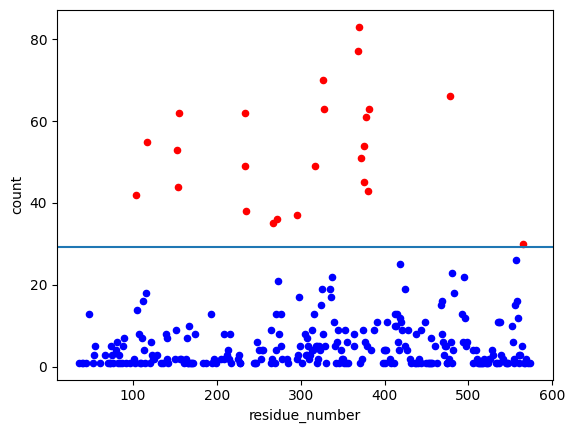

In [ ]:
# Makes one plot with an axis "ax" which we can add several plots to
fig, ax = plt.subplots()

two_std_value = std_value * 2

lt_data = res_interactions_count[res_interactions_count['count'] <= two_std_value]
lt_data.plot.scatter(
    x='residue_number',
    y='count',
    color='blue',
    ax=ax
)

gt_data = res_interactions_count[res_interactions_count['count'] > two_std_value]
gt_data.plot.scatter(
    x='residue_number',
    y='count',
    color='red',
    ax=ax
)

ax.axhline(two_std_value)

plt.show()
plt.close()

##**Finding the ligands that interact with these residues**

we only want the residue numbers that form the most interactions (over 2 standard deviations):

In [ ]:
# Select the rows where the count is greater than two standard deviations
all_data_over_two_std = res_interactions_count[
    res_interactions_count['count'] > two_std_value
]

# Sort the data by count in descending order
all_data_over_two_std = all_data_over_two_std.sort_values(
    by='count',
    ascending=False
)

residue_numbers_over_two_std = all_data_over_two_std['residue_number']
print(residue_numbers_over_two_std)

164    369
163    368
139    326
231    478
141    328
175    381
88     234
55     155
172    378
38     117
170    376
53     152
166    372
130    317
87     233
169    375
54     153
174    380
28     103
89     235
114    296
105    272
101    267
284    565
Name: residue_number, dtype: int64


What ligands interact with these residues?

Now we want to get all ligand_accessions which interact with a residue in residue_numbers_over_two_std.

In [ ]:
substantially_interacting_ligands  = df_lig_prot_interactions[
    df_lig_prot_interactions['residue_number'].isin(residue_numbers_over_two_std)
]['ligand_accession']

# Only report unique ligands
unique_substantially_int_ligs = list(substantially_interacting_ligands.unique())

print(unique_substantially_int_ligs)

['LWL', 'THA', 'AA', '4IX', '4J1', 'A1IAS', 'HLO', 'CVZ', 'E20', 'H0R', 'H1R', 'H0L', '1YK', '1YL', 'LWU', 'EBW', 'QRH', 'FP1', 'HUP', 'MES', 'PQY', 'EPE', 'FUL', 'A1CDA', 'A1CD5', 'WW2', 'GNT', 'HUW', 'ACT', '1PE', 'GD8', 'L1M', 'L0S', 'NA', 'L2Y', 'UCJ', 'EFS', 'NWA', 'DEP', 'UCY', 'ELT', 'EDO', 'LND', '3VI', 'PE8', 'PQV', 'ZN', '7PE', 'VX', 'HI6', 'DMS', 'NAG', 'FUC', 'MG', 'SO4', 'CL', 'NO3', 'GOL']


For our analysis it's worth seeing which ligands are not in our list

In [ ]:
# all_ligands
all_ligands = list(df_lig_prot_interactions['ligand_accession'].unique())

# List comprehension to find all ligands which have a functional role
missing_ligands = [x for x in all_ligands if x not in unique_substantially_int_ligs]
missing_ligands

['GAL', 'A1AAJ', 'GIV', 'BR', 'PEG', 'SIA']

We will select only ligands which interact the most in the initial data.

In [ ]:
df_res_lig_interactions = df_lig_prot_interactions.groupby(['residue_number', 'ligand_accession'])

df_res_lig_interactions = df_res_lig_interactions['interaction_ratio'].mean().reset_index()
df_res_lig_interactions

,residue_number,ligand_accession,interaction_ratio
0,36,NA,1.0
1,39,NA,1.0
2,40,MG,0.2
3,44,CL,0.1
4,47,CL,0.6
...,...,...,...
1045,568,NA,1.0
1046,569,CL,0.1
1047,569,MG,0.2
1048,571,NA,1.0


Now we can plot the ligand interactions of those ligands which interact with the most interacting residues.

We will put each ligand on a row and scale the interactions by the percentage of PDB entries they are seen in.

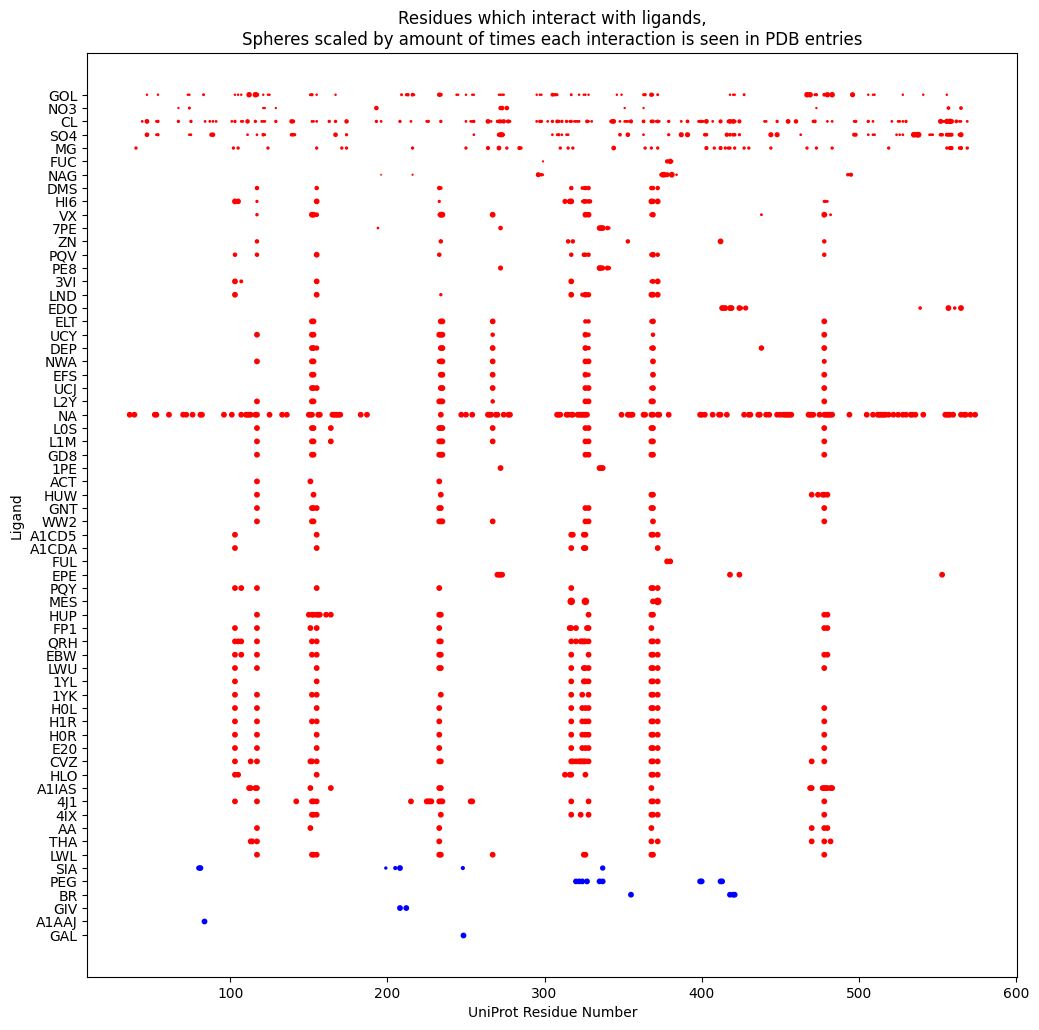

In [ ]:
# prepare a figure
fig, ax = plt.subplots(figsize=(12, 12))

# plot the less interesting ligands in blue
for ligand in missing_ligands:
    lig_prot_interactions = df_res_lig_interactions[df_res_lig_interactions['ligand_accession'] == ligand]
    lig_prot_interactions.plot.scatter(
        x='residue_number',
        y='ligand_accession',
        ax=ax,
        s=lig_prot_interactions['interaction_ratio']*10,
        c='blue'
    )

# plot the interesting ligands in red
for ligand in unique_substantially_int_ligs:
    lig_prot_interactions = df_res_lig_interactions[df_res_lig_interactions['ligand_accession'] == ligand]
    lig_prot_interactions.plot.scatter(
        x='residue_number',
        y='ligand_accession',
        ax=ax,
        s=lig_prot_interactions['interaction_ratio']*10,
        c='red'
    )

plt.ylabel('Ligand')
plt.xlabel('UniProt Residue Number')
plt.title('Residues which interact with ligands,\nSpheres scaled by amount of times each interaction is seen in PDB entries')
plt.show()
plt.close()

#**PDBe Macromolecular Interactions for a given protein**

This tutorial will guide you through searching PDBe for macromolecular interactions programmatically.

##**Obtaining data**
Now we are ready to find all the macromolecular interactions that a protein in the PDB archive forms.

We will get the macromolecular interactions of Human Acetylcholinesterase, which has the UniProt accession P22303.

In [ ]:
BASE_URL = "https://www.ebi.ac.uk/pdbe/"
PDBEKB_UNIPROT_URL = BASE_URL + "graph-api/uniprot/"

def get_macromolecule_interaction_data(uniprot_accession):
    """
    Get all the macromolecule interaction data for a given UniProt accession
    """

    url = PDBEKB_UNIPROT_URL + "interface_residues/" + uniprot_accession
    print(url)

    data = get_url(url=url)
    data_to_ret = []

    for data_uniprot_accession in data:
        accession_data = data.get(data_uniprot_accession)
        length = accession_data['length']

        for row in accession_data['data']:


            interaction_accession = row['accession']
            all_pdb_entries = [] #row['allPDBEntries']
            name = row['name']

            # Get the accession type, return empty dictionary if not present
            accession_type = row.get('additionalData', {})
            accession_type = accession_type['type']

            for residue in row.get('residues', []):

                if all_pdb_entries == []:
                    all_pdb_entries = residue['allPDBEntries']

                residue['interaction_accession'] = interaction_accession
                residue['interaction_name'] = name
                residue['length'] = length
                residue['uniprot_accession'] = uniprot_accession
                residue['interaction_accession_type'] = accession_type

                # Get the interacting PDB entries, return empty list if not present
                interacting_entries = residue.get('interactingPDBEntries', [])
                residue['interacting_pdb_entries'] = interacting_entries
                residue['interaction_ratio'] = len(
                    interacting_entries
                ) / len(
                    all_pdb_entries
                )
                residue['allPDBEntries'] = all_pdb_entries
                data_to_ret.append(residue)

    return data_to_ret


def explode_dataset(result, column_to_explode=None):

    df = pd.DataFrame(result)
    if column_to_explode:
        df = df.explode(column=column_to_explode).reset_index(drop=True)
    else:
        for column in df.select_dtypes(include='object'):
            df = df.explode(column=column).reset_index(drop=True)
    return df

In [ ]:
interaction_data = get_macromolecule_interaction_data(uniprot_accession="P22303")

pprint(interaction_data[0])

https://www.ebi.ac.uk/pdbe/graph-api/uniprot/interface_residues/P22303
{'allPDBEntries': ['6o5r',
                   '6o69',
                   '7p1p',
                   '4ey8',
                   '6cqu',
                   '6cqt',
                   '8aev',
                   '6zwe',
                   '4ey6',
                   '6nth',
                   '6cqz',
                   '6u3p',
                   '7d9o',
                   '5hf5',
                   '6ntl',
                   '7rb6',
                   '6o5v',
                   '7p1n',
                   '1f8u',
                   '4m0f',
                   '7d9p',
                   '7d9q',
                   '7rb5',
                   '6wuy',
                   '8dt2',
                   '8dt4',
                   '6cqx',
                   '6ntn',
                   '6ntg',
                   '6wvc',
                   '7rb7',
                   '9f6r',
                   '4ey7',
                   '1b41',
           

##**Reformatting the data**
The output results of the query contain all the information about the macromolecular interactions, however it is in a complex nested list that makes it difficult to parse without reformatting.

The following code simplifies the data, flattening the nested format:

In [ ]:
# Reformat data to make it a list of the macromolecular interactions found in the PDB archive for the protein
df_all_interactions = explode_dataset(
    result=interaction_data,
    column_to_explode='interactingPDBEntries'
)

In [ ]:
df_all_interactions.head()

,startIndex,endIndex,startCode,endCode,indexType,interactingPDBEntries,allPDBEntries,interaction_accession,interaction_name,length,uniprot_accession,interaction_accession_type,interacting_pdb_entries,interaction_ratio
0,56,56,PRO,PRO,UNIPROT,"{'pdbId': '7p1n', 'entityId': 2, 'chainIds': '...","[6o5r, 6o69, 7p1p, 4ey8, 6cqu, 6cqt, 8aev, 6zw...",P22303,Acetylcholinesterase,614,P22303,UNP,"[{'pdbId': '7p1n', 'entityId': 2, 'chainIds': ...",0.025974
1,56,56,PRO,PRO,UNIPROT,"{'pdbId': '7p1p', 'entityId': 2, 'chainIds': '...","[6o5r, 6o69, 7p1p, 4ey8, 6cqu, 6cqt, 8aev, 6zw...",P22303,Acetylcholinesterase,614,P22303,UNP,"[{'pdbId': '7p1n', 'entityId': 2, 'chainIds': ...",0.025974
2,74,74,GLY,GLY,UNIPROT,"{'pdbId': '7p1n', 'entityId': 2, 'chainIds': '...","[6o5r, 6o69, 7p1p, 4ey8, 6cqu, 6cqt, 8aev, 6zw...",P22303,Acetylcholinesterase,614,P22303,UNP,"[{'pdbId': '7p1n', 'entityId': 2, 'chainIds': ...",0.025974
3,74,74,GLY,GLY,UNIPROT,"{'pdbId': '7p1p', 'entityId': 2, 'chainIds': '...","[6o5r, 6o69, 7p1p, 4ey8, 6cqu, 6cqt, 8aev, 6zw...",P22303,Acetylcholinesterase,614,P22303,UNP,"[{'pdbId': '7p1n', 'entityId': 2, 'chainIds': ...",0.025974
4,75,75,PRO,PRO,UNIPROT,"{'pdbId': '7p1n', 'entityId': 2, 'chainIds': '...","[6o5r, 6o69, 7p1p, 4ey8, 6cqu, 6cqt, 8aev, 6zw...",P22303,Acetylcholinesterase,614,P22303,UNP,"[{'pdbId': '7p1n', 'entityId': 2, 'chainIds': ...",0.025974


##Exploring the data

The following code lists all the unique macromolecules (UniProt IDs) that interact with human Acetylcholinesterase in the PDB archive:

In [ ]:

df_all_interactions[['interaction_accession', 'interaction_name' ]].drop_duplicates()

,interaction_accession,interaction_name
0,P22303,Acetylcholinesterase
1872,P0C1Z0,Fasciculin-2
1991,Q9Y215,Acetylcholinesterase collagenic tail peptide


Now, you can do similar analysis as you did in ligand interactions.

Investigate if there is an overlap in drug-binding and macro-molecular binding site.